# CardioScope — Phase 1: Data exploration

Dataset: *Extension of Z-Alizadeh Sani* (UCI), 303 patients.
Targets: overall CAD (`Cath`) and stenosis of the three main coronary arteries (`LAD`, `LCX`, `RCA`).

This notebook only **describes** the data. Nothing computed here (e.g. correlations with the targets)
is used to choose features for the models — that would leak information. Any feature selection
happens inside the cross-validation folds in Phase 2.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

from cardioscope_ml import config
from cardioscope_ml.data import load_raw, clean

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
FIG = config.PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

paths = config.dataset_paths()
print("Sheets:", pd.ExcelFile(paths.raw).sheet_names)
raw = load_raw()
raw.shape

Sheets: ['Sheet 1 - Table 1', 'Sheet1']


(303, 59)

## 1. Columns, types and raw value encodings

In [2]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "values / range": [
        ", ".join(map(str, sorted(raw[c].unique(), key=str))) if raw[c].nunique() <= 6
        else f"{raw[c].min()} … {raw[c].max()}"
        for c in raw.columns
    ],
})
summary

,dtype,n_unique,missing,values / range
Age,int64,46,0,30 … 86
Weight,int64,54,0,48 … 120
Length,int64,44,0,140 … 188
Sex,str,2,0,"Fmale, Male"
BMI,float64,263,0,18.115412710007302 … 40.90065778377467
DM,int64,2,0,"0, 1"
HTN,int64,2,0,"0, 1"
Current Smoker,int64,2,0,"0, 1"
EX-Smoker,int64,2,0,"0, 1"
FH,int64,2,0,"0, 1"


In [3]:
print("Total missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Constant columns:", [c for c in raw if raw[c].nunique() == 1])

Total missing values: 0
Duplicate rows: 0
Constant columns: ['Exertional CP']


**Encoding quirks found**
- Binary flags use two styles: `0/1` (e.g. DM, HTN, Q Wave) and `Y/N` (e.g. CRF, LVH, Dyspnea).
- `Sex` is `Male` / `Fmale` (typo in source).
- `BBB` has three levels (N / LBBB / RBBB); `VHD` is ordinal (N < mild < Moderate < Severe).
- `Exertional CP` is "N" for every patient → no information.
- Workbook has a second, empty sheet `Sheet1`.

All mappings are defined in `ml/configs/features.yaml` and applied by `cardioscope_ml.data.clean`.

In [4]:
df = clean(raw)
F = config.model_feature_ids()
T = config.target_ids()
specs = {f["id"]: f for f in config.feature_specs()}
num = [f for f in F if specs[f]["type"] == "numeric"]
binary = [f for f in F if specs[f]["type"] == "binary"]
print(f"{len(F)} model features ({len(num)} numeric, {len(binary)} binary, "
      f"{len(F) - len(num) - len(binary)} ordinal/categorical); targets: {T}")
df.head()

54 model features (21 numeric, 29 binary, 4 ordinal/categorical); targets: ['cad', 'lad', 'lcx', 'rca']


,patient_id,age,sex,weight,height,bmi,dm,htn,current_smoker,ex_smoker,...,lymph,neut,plt,ef_tte,region_rwma,vhd,cad,lad,lcx,rca
0,0,53.0,1,90.0,175.0,29.387755,0,1,1,0,...,39.0,52.0,261.0,50.0,0,0,1,1,0,1
1,1,67.0,0,70.0,157.0,28.398718,0,1,0,0,...,38.0,55.0,165.0,40.0,4,0,1,1,1,0
2,2,54.0,1,54.0,164.0,20.077335,0,0,1,0,...,38.0,60.0,230.0,40.0,2,1,1,1,0,0
3,3,66.0,0,67.0,158.0,26.838648,0,1,0,0,...,18.0,72.0,742.0,55.0,0,3,0,0,0,0
4,4,50.0,0,87.0,153.0,37.165193,0,1,0,0,...,55.0,39.0,274.0,50.0,0,3,0,0,0,0


## 2. Numeric features: distribution, outliers and normal ranges

In [5]:
rows = []
for f in num:
    s = df[f]
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    n_iqr = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    lo, hi = (specs[f].get("normal_range") or [None, None])
    outside = None
    if "normal_range" in specs[f]:
        m = pd.Series(False, index=s.index)
        if lo is not None: m |= s < lo
        if hi is not None: m |= s > hi
        outside = round(100 * m.mean(), 1)
    rows.append(dict(feature=f, unit=specs[f].get("unit"), mean=s.mean(), median=s.median(),
                     min=s.min(), max=s.max(), skew=s.skew(), iqr_outliers=n_iqr,
                     normal_range=specs[f].get("normal_range"), pct_outside_normal=outside))
num_summary = pd.DataFrame(rows).set_index("feature").round(2)
num_summary

,unit,mean,median,min,max,skew,iqr_outliers,normal_range,pct_outside_normal
feature,,,,,,,,,
age,years,58.90,58.00,30.00,86.0,0.13,0,None,NaN
weight,kg,73.83,74.00,48.00,120.0,0.42,3,None,NaN
height,cm,164.72,165.00,140.00,188.0,-0.03,0,None,NaN
bmi,kg/m²,27.25,26.78,18.12,40.9,0.43,6,"[18.5, 24.9]",70.6
bp,mmHg,129.55,130.00,90.00,190.0,0.57,9,"[90, 120]",60.4
pr,beats/min,75.14,70.00,50.00,110.0,1.08,13,"[60, 100]",1.7
fbs,mg/dL,119.18,98.00,62.00,400.0,2.28,30,"[70, 99]",49.8
cr,mg/dL,1.06,1.00,0.50,2.2,0.95,8,"[0.6, 1.2]",20.1
tg,mg/dL,150.34,122.00,37.00,1050.0,3.78,16,"[None, 150]",34.7


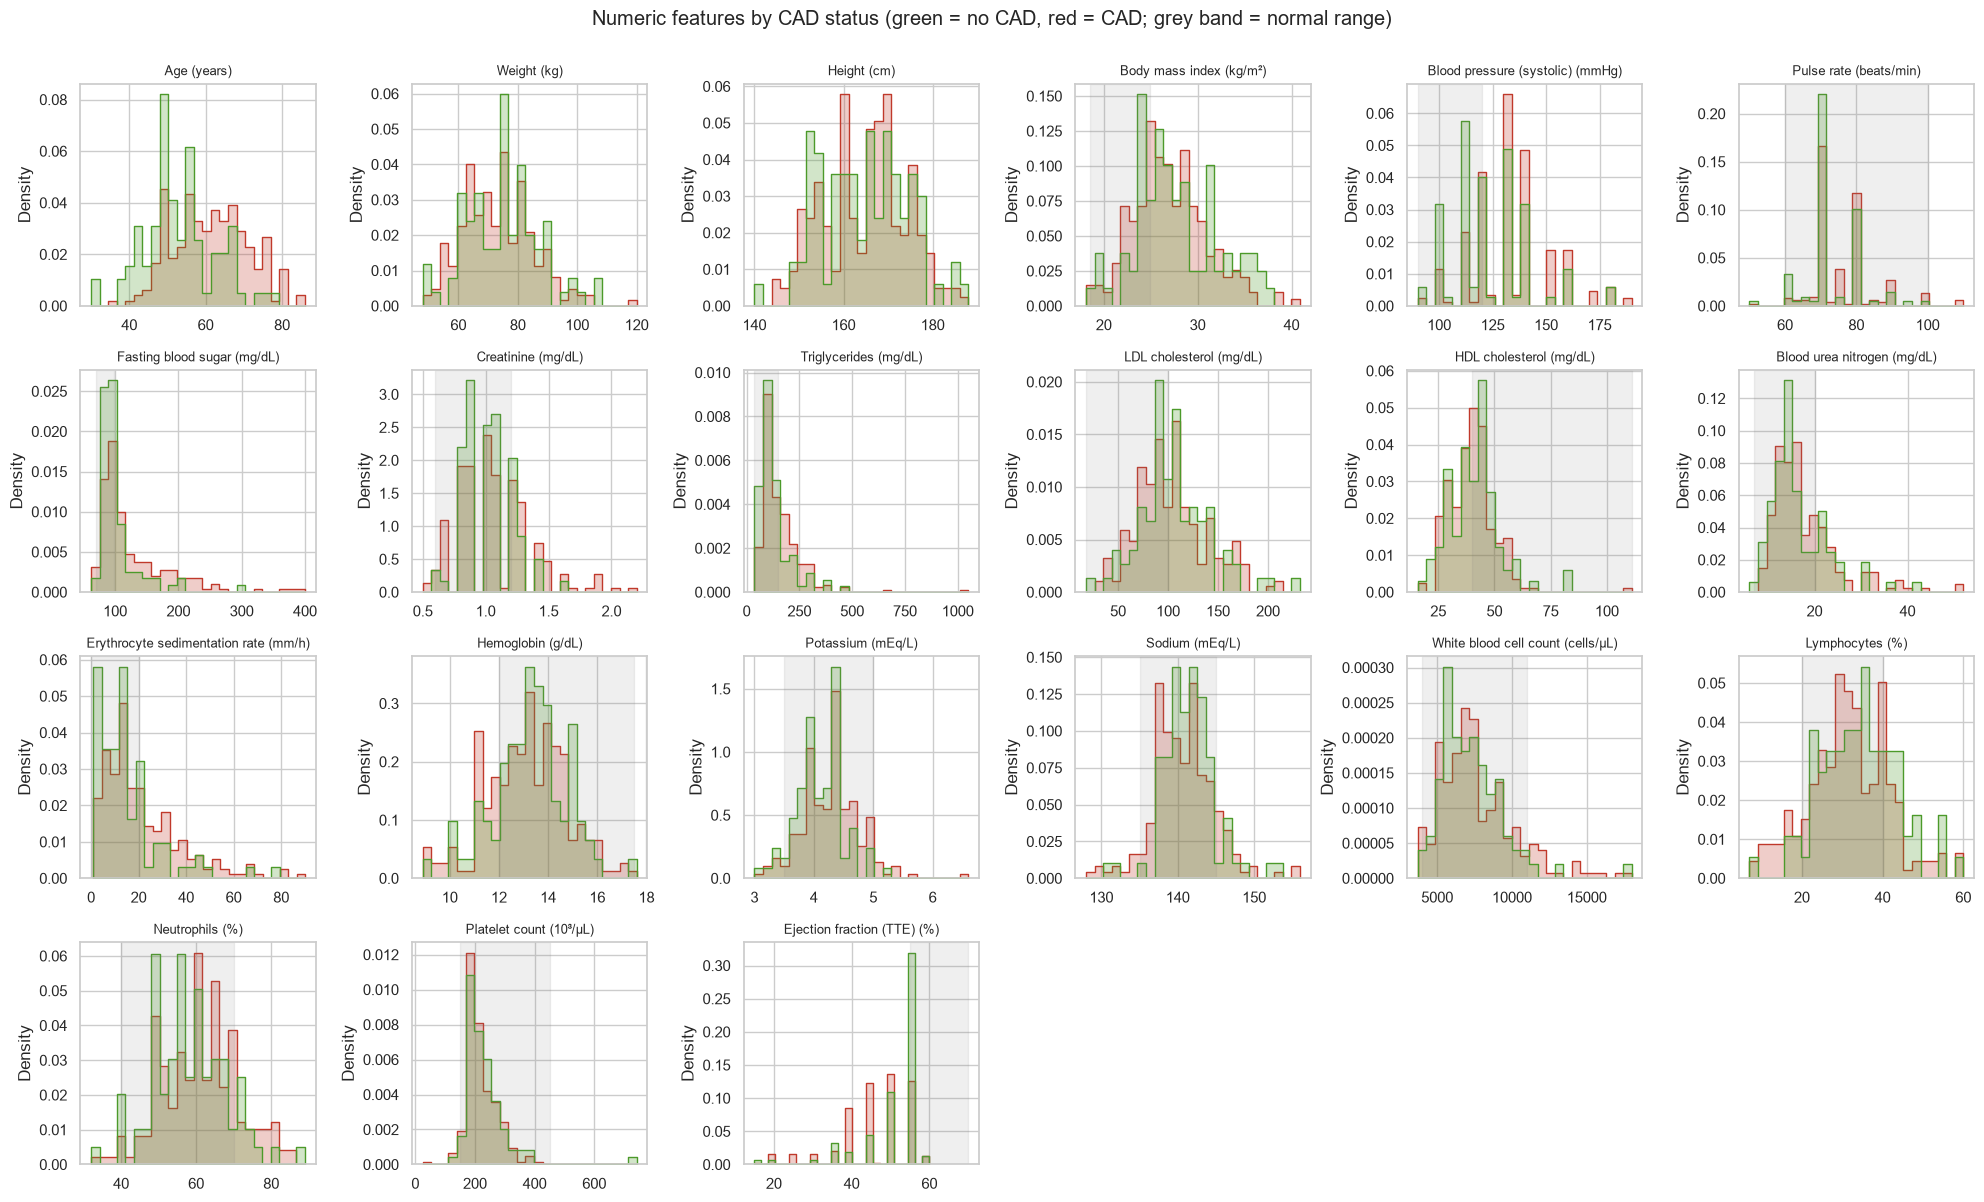

In [6]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12))
for ax, f in zip(axes.flat, num):
    sns.histplot(data=df, x=f, hue="cad", bins=25, ax=ax, element="step", stat="density",
                 common_norm=False, palette={0: "#4C9A2A", 1: "#C0392B"}, legend=False)
    r = specs[f].get("normal_range")
    if r:
        ax.axvspan(r[0] if r[0] is not None else df[f].min(), r[1] if r[1] is not None else df[f].max(),
                   color="grey", alpha=.12)
    ax.set_title(f"{specs[f]['label']} ({specs[f].get('unit') or ''})", fontsize=9)
    ax.set_xlabel("")
for ax in axes.flat[len(num):]:
    ax.axis("off")
fig.suptitle("Numeric features by CAD status (green = no CAD, red = CAD; grey band = normal range)", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "phase1_numeric_distributions.png", dpi=120, bbox_inches="tight")

Outliers by the 1.5×IQR rule exist (e.g. TG up to 1050 mg/dL, FBS up to 400 mg/dL, PLT down to 25),
but every value is **clinically possible** and inside the hard `valid_range` in features.yaml.
They are real patients, not data-entry errors, so we **keep them**. Tree models are robust to them;
for logistic regression, scaling is done inside CV folds in Phase 2.

## 3. Binary / ordinal / categorical features: prevalence

In [7]:
cat_rows = []
for f in F:
    if specs[f]["type"] == "numeric":
        continue
    vc = df[f].value_counts().sort_index()
    cat_rows.append(dict(feature=f, type=specs[f]["type"], group=specs[f]["group"],
                         counts=dict(vc), minority_n=int(vc.min())))
cat_summary = pd.DataFrame(cat_rows).set_index("feature").sort_values("minority_n")
cat_summary

,type,group,counts,minority_n
feature,,,,
chf,binary,history,"{0: 302, 1: 1}",1
function_class,ordinal,exam,"{0: 211, 1: 1, 2: 73, 3: 18}",1
lowth_ang,binary,exam,"{0: 301, 1: 2}",2
cva,binary,history,"{0: 298, 1: 5}",5
weak_peripheral_pulse,binary,exam,"{0: 298, 1: 5}",5
crf,binary,history,"{0: 297, 1: 6}",6
thyroid_disease,binary,history,"{0: 296, 1: 7}",7
bbb,categorical,ecg,"{'LBBB': 13, 'N': 282, 'RBBB': 8}",8
diastolic_murmur,binary,exam,"{0: 294, 1: 9}",9


In [8]:
rare = cat_summary.query("minority_n < 15").index.tolist()
print("Features whose rarest value occurs in < 15 patients (unstable for modelling):", rare)

Features whose rarest value occurs in < 15 patients (unstable for modelling): ['chf', 'function_class', 'lowth_ang', 'cva', 'weak_peripheral_pulse', 'crf', 'thyroid_disease', 'bbb', 'diastolic_murmur', 'poor_r_progression', 'ex_smoker', 'lung_rales', 'airway_disease', 'vhd', 'edema', 'st_elevation', 'region_rwma']


## 4. Class balance of the four targets

In [9]:
bal = pd.DataFrame({t: df[t].value_counts().reindex([1, 0]) for t in T}).T
bal.columns = ["positive", "negative"]
bal["% positive"] = (100 * bal.positive / len(df)).round(1)
bal

,positive,negative,% positive
cad,216,87,71.3
lad,177,126,58.4
lcx,119,184,39.3
rca,114,189,37.6


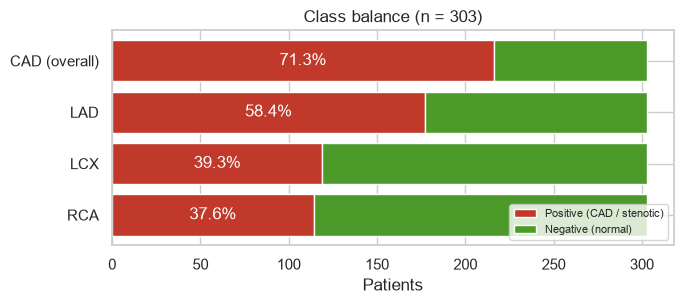

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = {"cad": "CAD (overall)", "lad": "LAD", "lcx": "LCX", "rca": "RCA"}
y = np.arange(len(T))
ax.barh(y, bal.positive, color="#C0392B", label="Positive (CAD / stenotic)")
ax.barh(y, bal.negative, left=bal.positive, color="#4C9A2A", label="Negative (normal)")
for i, t in enumerate(T):
    ax.text(bal.positive[t] / 2, i, f"{bal['% positive'][t]}%", va="center", ha="center", color="white")
ax.set_yticks(y, [labels[t] for t in T]); ax.invert_yaxis(); ax.set_xlabel("Patients")
ax.legend(loc="lower right", fontsize=8); ax.set_title("Class balance (n = 303)")
fig.tight_layout(); fig.savefig(FIG / "phase1_class_balance.png", dpi=120)

## 5. Overall CAD vs. the three vessel labels

In [11]:
v = df[["lad", "lcx", "rca"]]
df["n_vessels"] = v.sum(axis=1)
df["any_vessel"] = (df.n_vessels > 0).astype(int)
pd.crosstab(df.cad, df.any_vessel, rownames=["CAD (Cath)"], colnames=["any vessel stenotic"], margins=True)

any vessel stenotic,0,1,All
CAD (Cath),,,
0,86,1,87
1,0,216,216
All,86,217,303


In [12]:
exceptions = df[df.cad != df.any_vessel]
print(f"Patients where CAD != (any vessel stenotic): {len(exceptions)}")
raw.loc[exceptions.index, ["Age", "Sex", "Typical Chest Pain", "EF-TTE", "Region RWMA", "LAD", "LCX", "RCA", "Cath"]]

Patients where CAD != (any vessel stenotic): 1


,Age,Sex,Typical Chest Pain,EF-TTE,Region RWMA,LAD,LCX,RCA,Cath
93,65,Male,1,45,0,Stenotic,Normal,Normal,Normal


In [13]:
pd.crosstab(df.n_vessels, df.cad, rownames=["# stenotic vessels"], colnames=["CAD"], margins=True)

CAD,0,1,All
# stenotic vessels,,,
0,86,0,86
1,1,86,87
2,0,67,67
3,0,63,63
All,87,216,303


In [14]:
# How often vessels are diseased together (co-occurrence) and their correlation.
co = v.T @ v
print("Co-occurrence counts (diagonal = patients with that vessel stenotic):")
display(co)
print("Phi correlation between vessel labels:")
display(v.corr().round(2))
print("P(vessel stenotic | CAD):"); display(v[df.cad == 1].mean().round(3))

Co-occurrence counts (diagonal = patients with that vessel stenotic):


,lad,lcx,rca
lad,177,96,87
lcx,96,119,73
rca,87,73,114


Phi correlation between vessel labels:


,lad,lcx,rca
lad,1.00,0.36,0.28
lcx,0.36,1.00,0.39
rca,0.28,0.39,1.00


P(vessel stenotic | CAD):


lad    0.815
lcx    0.551
rca    0.528
dtype: float64

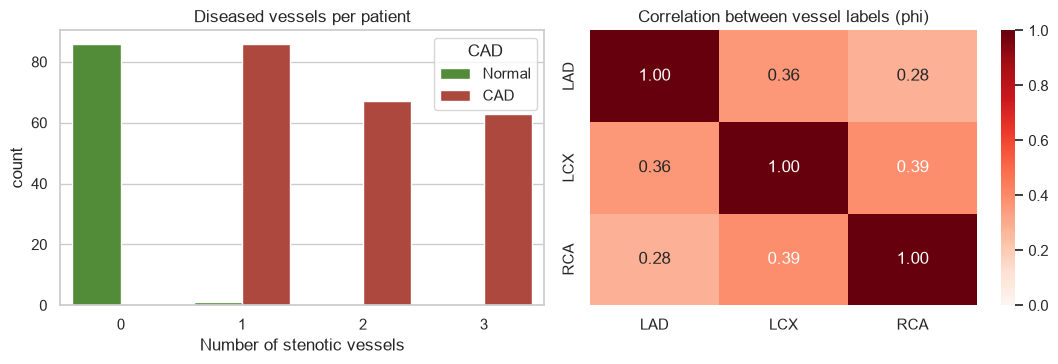

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(x="n_vessels", hue="cad", data=df, ax=axes[0], palette={0: "#4C9A2A", 1: "#C0392B"})
axes[0].set_xlabel("Number of stenotic vessels"); axes[0].set_title("Diseased vessels per patient")
axes[0].legend(title="CAD", labels=["Normal", "CAD"])
sns.heatmap(v.corr(), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[1],
            xticklabels=["LAD", "LCX", "RCA"], yticklabels=["LAD", "LCX", "RCA"])
axes[1].set_title("Correlation between vessel labels (phi)")
fig.tight_layout(); fig.savefig(FIG / "phase1_cad_vs_vessels.png", dpi=120)

## 6. Redundant and derived features

In [16]:
bmi_calc = df.weight / (df.height / 100) ** 2
print("max |BMI - weight/height²| =", float((bmi_calc - df.bmi).abs().max()))
print("Obesity == (BMI >= 25)  in", int((df.obesity == (df.bmi >= 24.99)).sum()), "of", len(df), "rows")
print("\nChest-pain type combinations (typical, atypical, nonanginal):")
print(df[["typical_chest_pain", "atypical", "nonanginal"]].value_counts())
print("\nCurrent & ex-smoker at the same time:", int((df.current_smoker & df.ex_smoker).sum()))

max |BMI - weight/height²| = 0.0
Obesity == (BMI >= 25)  in 303 of 303 rows

Chest-pain type combinations (typical, atypical, nonanginal):
typical_chest_pain  atypical  nonanginal
1                   0         0             164
0                   1         0              93
                    0         0              30
                              1              16
Name: count, dtype: int64

Current & ex-smoker at the same time: 0


## 7. Correlations

**7a. Between numeric/ordinal features** (Spearman, robust to skew and outliers).

,level_0,level_1,rho,abs_rho
449,neut,lymph,-0.91,0.91
73,bmi,weight,0.72,0.72
49,height,weight,0.45,0.45
324,hb,esr,-0.44,0.44
271,bun,cr,0.43,0.43
548,region_rwma,ef_tte,-0.38,0.38
572,vhd,ef_tte,-0.36,0.36
314,hb,height,0.36,0.36
448,neut,wbc,0.33,0.33
224,ldl,tg,0.33,0.33


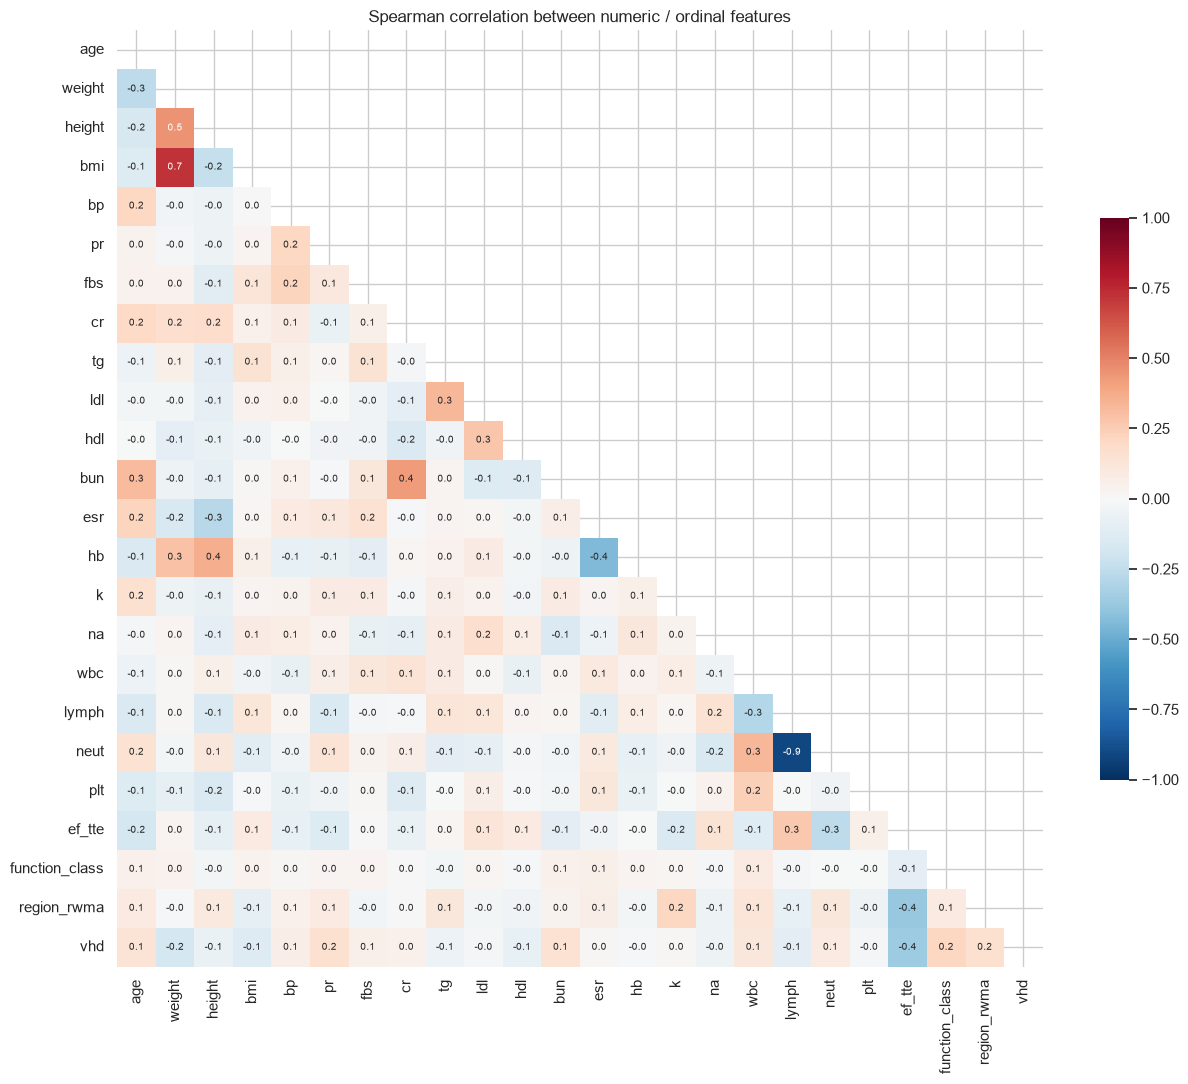

In [17]:
ordinal = [f for f in F if specs[f]["type"] == "ordinal"]
corr = df[num + ordinal].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .6})
ax.set_title("Spearman correlation between numeric / ordinal features")
fig.tight_layout(); fig.savefig(FIG / "phase1_feature_correlation.png", dpi=120)
pairs = (corr.where(~mask).stack().rename("rho").reset_index()
         .assign(abs_rho=lambda d: d.rho.abs()).sort_values("abs_rho", ascending=False))
pairs.head(10).round(2)

**7b. Association of each feature with each target.**
We report the univariate ROC-AUC of each feature on its own (0.5 = useless, 1.0 / 0.0 = perfectly
separating; values below 0.5 mean "lower value → more risk") and the Spearman correlation.
This is descriptive only — **not** used for feature selection.

In [18]:
X = df[F].copy()
X["bbb"] = (X.bbb != "N").astype(int)   # any bundle-branch block, for this summary only
assoc = {}
for t in T:
    auc = X.apply(lambda c: roc_auc_score(df[t], c))
    rho = X.apply(lambda c: c.corr(df[t], method="spearman"))
    assoc[(t, "auc")] = auc
    assoc[(t, "rho")] = rho
assoc = pd.DataFrame(assoc)
strength = pd.DataFrame({t: (assoc[(t, "auc")] - .5).abs() for t in T})
top = strength.max(axis=1).sort_values(ascending=False).index[:20]
assoc.loc[top].round(2)

cad         lad         lcx         rca      
                     auc   rho   auc   rho   auc   rho   auc   rho
typical_chest_pain  0.80  0.54  0.73  0.46  0.65  0.29  0.65  0.29
age                 0.72  0.35  0.68  0.30  0.68  0.31  0.63  0.23
atypical            0.29 -0.42  0.33 -0.35  0.42 -0.17  0.39 -0.24
ef_tte              0.31 -0.30  0.29 -0.37  0.41 -0.15  0.42 -0.13
region_rwma         0.67  0.34  0.68  0.38  0.56  0.14  0.54  0.08
bp                  0.66  0.26  0.60  0.17  0.62  0.20  0.56  0.10
htn                 0.66  0.29  0.59  0.18  0.59  0.17  0.57  0.15
fbs                 0.65  0.24  0.58  0.14  0.59  0.15  0.60  0.17
neut                0.58  0.12  0.61  0.19  0.54  0.07  0.64  0.23
esr                 0.63  0.21  0.62  0.21  0.57  0.12  0.61  0.19
lymph               0.42 -0.12  0.39 -0.19  0.47 -0.04  0.37 -0.22
dm                  0.63  0.25  0.56  0.12  0.57  0.16  0.63  0.27
t_inversion         0.62  0.24  0.60  0.21  0.53  0.07  0.53  0.06
tg                  0.62  0.18  0.57  0.12  0.59  0.15  0.57  0.11
k                   0.61  0.18  0.56  0.10  0.56  0.09  0.56  0.10
pr                  0.60  0.17  0.60  0.18  0.52  0.04  0.53  0.06
plt                 0.46 -0.07  0.48 -0.04  0.40 -0.17  0.46 -0.06
wbc                 0.53  0.05  0.57  0.12  0.51  0.02  0.58  0.14
cr                  0.54  0.06  0.53  0.05  0.58  0.14  0.56  0.10
na                  0.44 -0.10  0.43 -0.12  0.56  0.10  0.44 -0.09

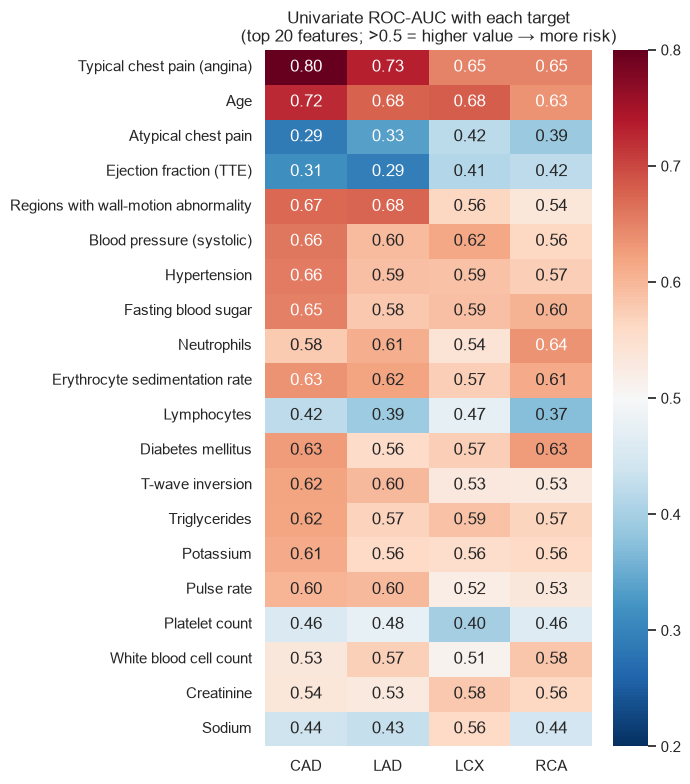

In [19]:
fig, ax = plt.subplots(figsize=(7, 8))
heat = pd.DataFrame({t.upper(): assoc[(t, "auc")] for t in T}).loc[top]
heat.index = [specs[f]["label"] for f in top]
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu_r", center=.5, vmin=.2, vmax=.8, ax=ax)
ax.set_title("Univariate ROC-AUC with each target\n(top 20 features; >0.5 = higher value → more risk)")
fig.tight_layout(); fig.savefig(FIG / "phase1_target_association.png", dpi=120)

In [20]:
for t in T:
    s = (assoc[(t, "auc")] - .5).abs().sort_values(ascending=False).head(6).index
    print(f"{t.upper():4s} strongest:", ", ".join(f"{f} (AUC {assoc.loc[f, (t, 'auc')]:.2f})" for f in s))

CAD  strongest: typical_chest_pain (AUC 0.80), age (AUC 0.72), atypical (AUC 0.29), ef_tte (AUC 0.31), region_rwma (AUC 0.67), bp (AUC 0.66)
LAD  strongest: typical_chest_pain (AUC 0.73), ef_tte (AUC 0.29), age (AUC 0.68), region_rwma (AUC 0.68), atypical (AUC 0.33), esr (AUC 0.62)
LCX  strongest: age (AUC 0.68), typical_chest_pain (AUC 0.65), bp (AUC 0.62), plt (AUC 0.40), fbs (AUC 0.59), tg (AUC 0.59)
RCA  strongest: typical_chest_pain (AUC 0.65), neut (AUC 0.64), age (AUC 0.63), lymph (AUC 0.37), dm (AUC 0.63), esr (AUC 0.61)


## 8. Summary
See `docs/phase1_data_findings.md` for the written summary of these results.